# Vehicle Insurance Cross Sell Classification

This is a vehicle insurance cross sell dataset. It has customer info like gender, age and region, vehicle info like vehicle age and damage, and policy info like annual premium and sales channel. The target is Response, 1 if the customer is interested in vehicle insurance and 0 if not. The goal is to predict who would want the offer, so the company can reach those customers first. We'll look into the data, do EDA, turn the categorical columns into numbers and try some classification algorithms to see which one is the best for this work.

In [1]:
import pandas as pd

train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

print("training data shape", train_df.shape)
print("test data shape", test_df.shape)


training data shape (381109, 12)
test data shape (127037, 11)


In [2]:
train_df.head()

,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,1,Male,44,1,28.0,0,> 2 Years,Yes,40454.0,26.0,217,1
1,2,Male,76,1,3.0,0,1-2 Year,No,33536.0,26.0,183,0
2,3,Male,47,1,28.0,0,> 2 Years,Yes,38294.0,26.0,27,1
3,4,Male,21,1,11.0,1,< 1 Year,No,28619.0,152.0,203,0
4,5,Female,29,1,41.0,1,< 1 Year,No,27496.0,152.0,39,0


In [3]:
test_df.head()

,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage
0,381110,Male,25,1,11.0,1,< 1 Year,No,35786.0,152.0,53
1,381111,Male,40,1,28.0,0,1-2 Year,Yes,33762.0,7.0,111
2,381112,Male,47,1,28.0,0,1-2 Year,Yes,40050.0,124.0,199
3,381113,Male,24,1,27.0,1,< 1 Year,Yes,37356.0,152.0,187
4,381114,Male,27,1,28.0,1,< 1 Year,No,59097.0,152.0,297


In [4]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 381109 entries, 0 to 381108
Data columns (total 12 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    381109 non-null  int64  
 1   Gender                381109 non-null  object 
 2   Age                   381109 non-null  int64  
 3   Driving_License       381109 non-null  int64  
 4   Region_Code           381109 non-null  float64
 5   Previously_Insured    381109 non-null  int64  
 6   Vehicle_Age           381109 non-null  object 
 7   Vehicle_Damage        381109 non-null  object 
 8   Annual_Premium        381109 non-null  float64
 9   Policy_Sales_Channel  381109 non-null  float64
 10  Vintage               381109 non-null  int64  
 11  Response              381109 non-null  int64  
dtypes: float64(3), int64(6), object(3)
memory usage: 34.9+ MB


In [5]:
train_df.describe()

,id,Age,Driving_License,Region_Code,Previously_Insured,Annual_Premium,Policy_Sales_Channel,Vintage,Response
count,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000
mean,190555.000000,38.822584,0.997869,26.388807,0.458210,30564.389581,112.034295,154.347397,0.122563
std,110016.836208,15.511611,0.046110,13.229888,0.498251,17213.155057,54.203995,83.671304,0.327936
min,1.000000,20.000000,0.000000,0.000000,0.000000,2630.000000,1.000000,10.000000,0.000000
25%,95278.000000,25.000000,1.000000,15.000000,0.000000,24405.000000,29.000000,82.000000,0.000000
50%,190555.000000,36.000000,1.000000,28.000000,0.000000,31669.000000,133.000000,154.000000,0.000000
75%,285832.000000,49.000000,1.000000,35.000000,1.000000,39400.000000,152.000000,227.000000,0.000000
max,381109.000000,85.000000,1.000000,52.000000,1.000000,540165.000000,163.000000,299.000000,1.000000


In [6]:
train_df["Vehicle_Age"].value_counts()

Vehicle_Age
1-2 Year     200316
< 1 Year     164786
> 2 Years     16007
Name: count, dtype: int64

In [7]:
vehicle_values = {"Yes": 1, "No": 0}

train_df["Vehicle_Damage"] = train_df["Vehicle_Damage"].map(vehicle_values)
test_df["Vehicle_Damage"] = test_df["Vehicle_Damage"].map(vehicle_values)

In [8]:
vehicle_age = {"< 1 Year": 0, "1-2 Year": 1, "> 2 Years": 2}

train_df["Vehicle_Age"] = train_df["Vehicle_Age"].map(vehicle_age)
test_df["Vehicle_Age"] = test_df["Vehicle_Age"].map(vehicle_age)

In [9]:
gender_values = {"Male": 1, "Female": 0}

train_df["Gender"] = train_df["Gender"].map(gender_values)
test_df["Gender"] = test_df["Gender"].map(gender_values)

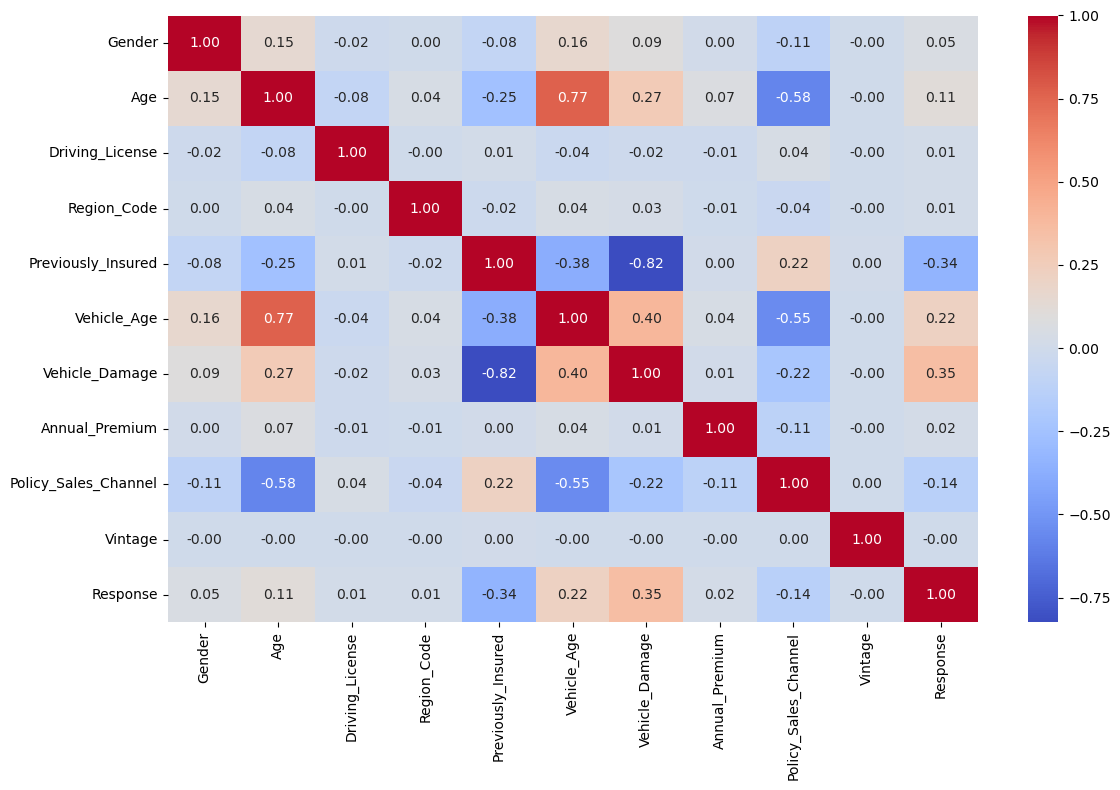

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))
sns.heatmap(train_df.drop(columns="id").corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")
plt.tight_layout()
plt.show()

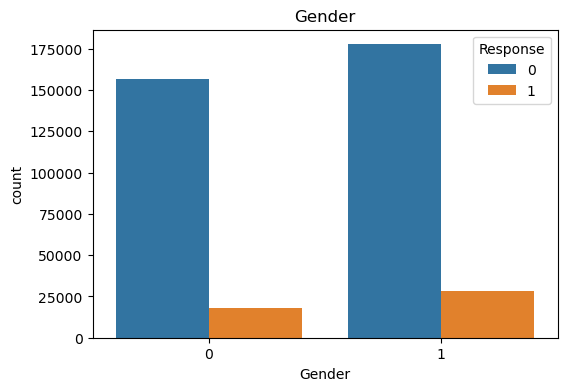

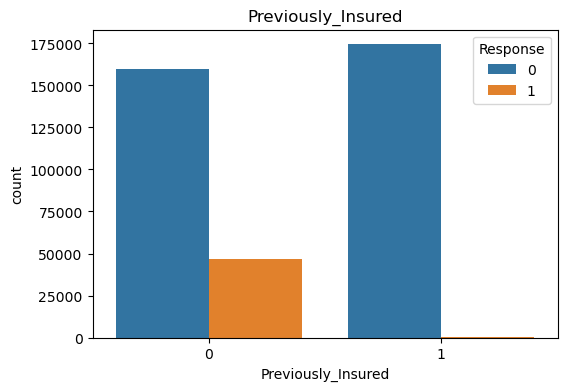

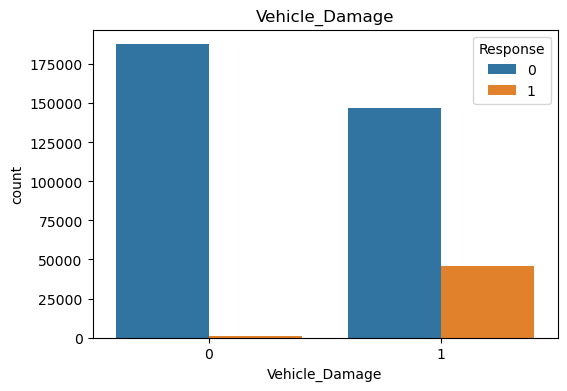

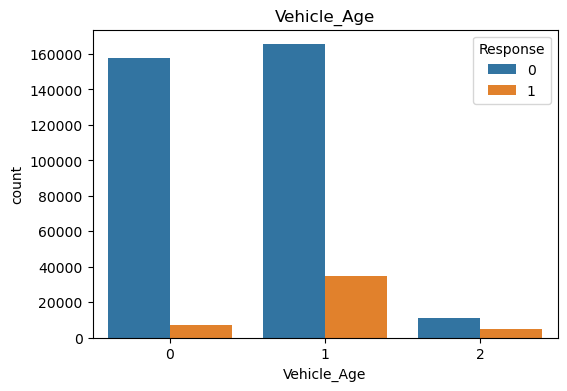

In [11]:
for col in ["Gender", "Previously_Insured", "Vehicle_Damage", "Vehicle_Age"]:
    plt.figure(figsize=(6, 4))
    sns.countplot(data=train_df, x=col, hue="Response")
    plt.title(col)
    plt.show()

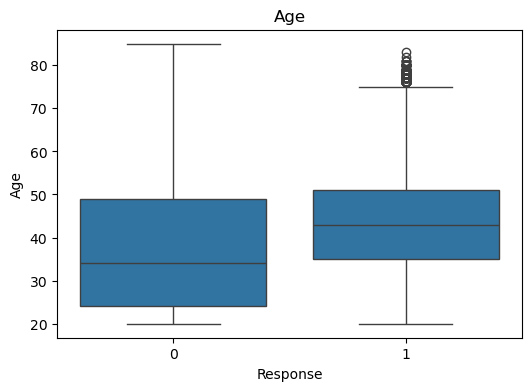

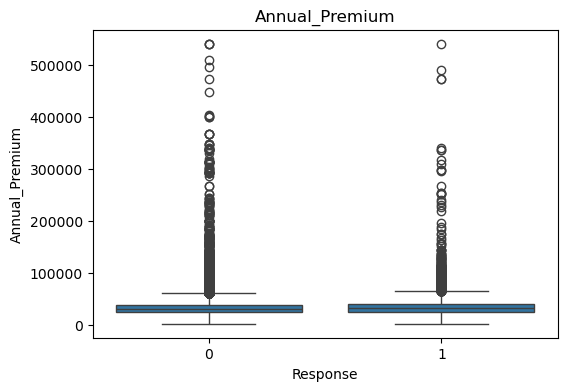

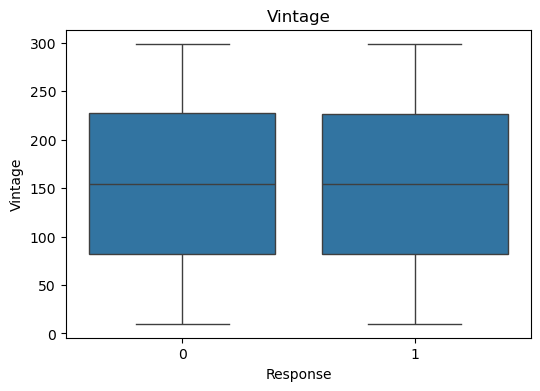

In [12]:
for col in ["Age", "Annual_Premium", "Vintage"]:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=train_df, x="Response", y=col)
    plt.title(col)
    plt.show()

In [14]:
x = train_df.drop(columns=["id", "Response"])
y = train_df["Response"]

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split
import joblib

def algo_test(x, y):
    modeller = [
        LogisticRegression(max_iter=2000, class_weight="balanced"),
        DecisionTreeClassifier(random_state=42, class_weight="balanced"),
        RandomForestClassifier(random_state=42, class_weight="balanced", n_jobs=-1),
        GradientBoostingClassifier(random_state=42),
        AdaBoostClassifier(random_state=42),
    ]
    isimler = [
        "LogisticRegression",
        "DecisionTreeClassifier",
        "RandomForestClassifier",
        "GradientBoostingClassifier",
        "AdaBoostClassifier",
    ]

    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.20, random_state=42, stratify=y
    )

    accuracy, precision, recall, f1, mdl = [], [], [], [], []

    for model in modeller:
        model.fit(x_train, y_train)
        tahmin = model.predict(x_test)
        mdl.append(model)
        accuracy.append(accuracy_score(y_test, tahmin))
        precision.append(precision_score(y_test, tahmin, pos_label=1, zero_division=0))
        recall.append(recall_score(y_test, tahmin, pos_label=1, zero_division=0))
        f1.append(f1_score(y_test, tahmin, pos_label=1, zero_division=0))

    metrics = pd.DataFrame(
        {"Accuracy": accuracy, "Precision": precision, "Recall": recall, "F1": f1, "Model": mdl},
        index=isimler,
    )
    metrics.sort_values("F1", ascending=False, inplace=True)
    return metrics, x_test, y_test

metrics, x_test, y_test = algo_test(x, y)
metrics.drop("Model", axis=1)

c:\Users\Administrator\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,Accuracy,Precision,Recall,F1
LogisticRegression,0.639172,0.250611,0.976772,0.398881
DecisionTreeClassifier,0.829813,0.293609,0.276386,0.284738
RandomForestClassifier,0.868253,0.361878,0.098159,0.154429
GradientBoostingClassifier,0.877384,0.250000,0.000214,0.000428
AdaBoostClassifier,0.877437,0.000000,0.000000,0.000000


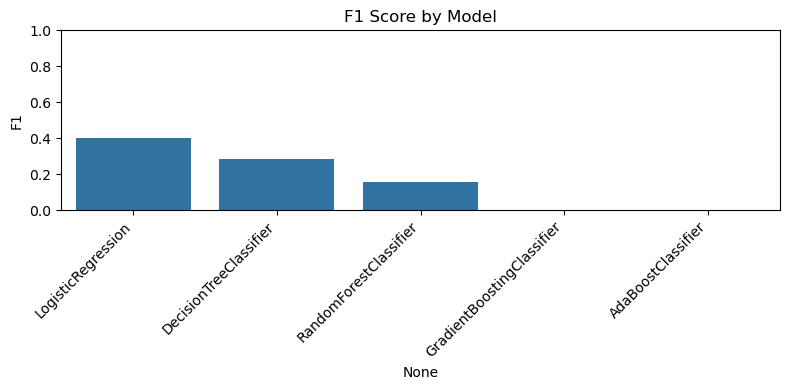

In [16]:
plt.figure(figsize=(8, 4))
sns.barplot(x=metrics.index, y=metrics["F1"])
plt.title("F1 Score by Model")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

Best model: LogisticRegression
              precision    recall  f1-score   support

           0       0.99      0.59      0.74     66880
           1       0.25      0.98      0.40      9342

    accuracy                           0.64     76222
   macro avg       0.62      0.78      0.57     76222
weighted avg       0.90      0.64      0.70     76222



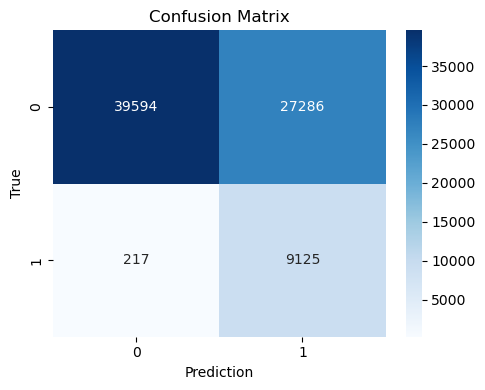

In [17]:
best = metrics.iloc[0]["Model"]
pred = best.predict(x_test)

print("Best model:", metrics.index[0])
print(classification_report(y_test, pred, zero_division=0))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Prediction")
plt.ylabel("True")
plt.tight_layout()
plt.show()

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

tf.keras.utils.set_random_seed(42)

x_train, x_test, y_train, y_test = train_test_split(
    x.astype(float), y, test_size=0.20, random_state=42, stratify=y
)

x_scaler = StandardScaler()
x_tr = x_scaler.fit_transform(x_train)
x_te = x_scaler.transform(x_test)
y_tr = y_train.to_numpy()

weights = compute_class_weight("balanced", classes=np.unique(y_tr), y=y_tr)
class_weight = dict(zip(np.unique(y_tr), weights))

dl = keras.Sequential([
    keras.layers.Input(shape=(x_tr.shape[1],)),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid"),
])
dl.compile(optimizer="adam", loss="binary_crossentropy")
dl.fit(
    x_tr, y_tr,
    validation_split=0.2,
    epochs=30,
    batch_size=1024,
    class_weight=class_weight,
    callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)],
    verbose=0,
)

pred = (dl.predict(x_te, verbose=0).ravel() >= 0.5).astype(int)
print("Accuracy :", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred, pos_label=1, zero_division=0))
print("Recall   :", recall_score(y_test, pred, pos_label=1, zero_division=0))
print("F1       :", f1_score(y_test, pred, pos_label=1, zero_division=0))
print(classification_report(y_test, pred, zero_division=0))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues")
plt.title("Deep Learning Confusion Matrix")
plt.xlabel("Prediction")
plt.ylabel("True")
plt.tight_layout()
plt.show()

NameError: name 'x' is not defined

In [18]:
joblib.dump(best, "insurance_model.joblib")

x_submit = test_df.drop(columns="id")
test_pred = best.predict(x_submit)

submission = pd.DataFrame({"id": test_df["id"], "Response": test_pred})
submission.to_csv("submission.csv", index=False)
submission.head()

,id,Response
0,381110,0
1,381111,1
2,381112,1
3,381113,0
4,381114,0
